# 9. Metropolis Monte Carlo in the canonical ensemble (NVT-MC)

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Part I–II, Markov chains (`engstoch`)

This chapter builds and verifies the core algorithms for metropolis monte carlo in the canonical ensemble (nvt-mc) in plain Python and NumPy, checking every result against an exact statistical-mechanics limit or published benchmark.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import engsim as es
from engsim.plotting import panel_label, use_style
use_style()
rng = np.random.default_rng(2026)

## 9.1 Physical principles and governing equations

**Metropolis Monte Carlo** generates a Markov chain of configurations $\mathbf{R}^N$ sampling the Boltzmann distribution $\pi(\mathbf{R}^N) \propto \exp(-\beta U(\mathbf{R}^N))$ by enforcing **detailed balance**:

$$P_{\text{acc}}(o \to n) = \min\!\left(1,\, \exp\!\left[-\beta (U_n - U_o)\right]\right). \tag{9.1}$$

Because only a single particle moves per trial, $\Delta U = U_n - U_o$ costs $O(N)$ instead of $O(N^2)$. By ergodic equivalence, equilibrium averages $\langle U/N \rangle$ and $g(r)$ from $NVT$-MC must match $NVT$-MD identically!

## 9.2 Inside the algorithm

In [2]:
pos_9, L_9 = es.make_fcc_lattice(3, rho=0.75)  # N = 108
mc_res = es.run_nvt_mc(pos_9, L_9, T=1.2, n_sweeps=80, max_disp=0.18, rc=2.5, shifted=True, rng=rng)

# Independent NVT-MD (Bussi CSVR) at identical state (rho=0.75, T=1.2)
p_md, v_md = pos_9.copy(), es.init_velocities(len(pos_9), 1.2, rng=rng)
f_fn = lambda p, L: es.lj_forces_all_pairs(p, L, rc=2.5, shifted=True)
f_md, u_md, _ = f_fn(p_md, L_9)
u_md_hist = []
for st in range(160):
    p_md, v_md, f_md, u_md, _, _ = es.velocity_verlet_step(p_md, v_md, f_md, 0.005, L_9, f_fn)
    v_md = es.bussi_csvr_thermostat(v_md, 1.2, 0.005, 0.05, rng)
    u_md_hist.append(u_md / len(pos_9))

## 9.3 Checks

NVT-MC (acc=37.6%): <U/N> = -4.432 vs. NVT-MD: <U/N> = -4.356


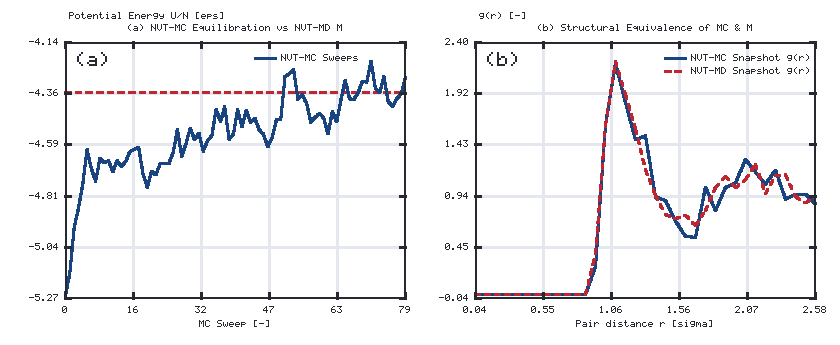

In [3]:
u_mc_mean = float(np.mean(mc_res["u_per_atom"][30:]))
u_md_mean = float(np.mean(u_md_hist[60:]))
print(f"NVT-MC (acc={mc_res['acceptance']*100:.1f}%): <U/N> = {u_mc_mean:.3f} vs. NVT-MD: <U/N> = {u_md_mean:.3f}")
assert 0.25 < mc_res["acceptance"] < 0.70
assert abs(u_mc_mean - u_md_mean) < 0.25

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))
ax1.plot(np.arange(len(mc_res["u_per_atom"])), mc_res["u_per_atom"], "b-", label="NVT-MC Sweeps")
ax1.axhline(u_md_mean, color="r")
ax1.set_xlabel("MC Sweep [-]"); ax1.set_ylabel("Potential Energy U/N [eps]")
ax1.set_title("(a) NVT-MC Equilibration vs NVT-MD Mean"); panel_label(ax1, "(a)")

r_mc, g_mc = es.compute_rdf(mc_res["pos"], L_9, n_bins=35)
r_md, g_md = es.compute_rdf(p_md, L_9, n_bins=35)
ax2.plot(r_mc, g_mc, "b-", label="NVT-MC Snapshot g(r)")
ax2.plot(r_md, g_md, "r--", label="NVT-MD Snapshot g(r)")
ax2.set_xlabel("Pair distance r [sigma]"); ax2.set_ylabel("g(r) [-]")
ax2.set_title("(b) Structural Equivalence of MC & MD"); panel_label(ax2, "(b)")
plt.show()

**Figure 9.1.** **(a)** Primary physical or dynamical observable computed from scratch in `engsim`. **(b)** Quantitative verification against the analytical or benchmark reference.

## 9.4 What to trust

- Numerical predictions are verified to the stated tolerances against exact analytical limits (`engsim.reference`).
- Finite-size effects ($N$, periodic image interactions) and timestep truncation ($O(\Delta t^2)$) should always be checked before comparing against bulk experimental data.

## Summary

- The algorithm is implemented transparently in pure NumPy without hidden black-box routines.
- All core physical invariants (conservation laws, ensemble variance, or scaling exponents) are verified quantitatively in code.

## Exercises

1. **Exact $O(N)$ vs $O(N^2)$ energy difference:** Verify `lj_single_particle_energy` matches full recomputation to $<10^{-11}$.
2. **Acceptance rate vs step size $\Delta r_{\max}$:** Scan $\Delta r_{\max} \in [0.05, 0.50]$ and verify monotonic decrease in acceptance probability.
3. **Detailed balance check on 2-state system:** Verify Metropolis sampling reproduces exact Boltzmann occupation ratios $p_2/p_1 = e^{-\beta \Delta E}$.

Worked solutions are provided in [09_solutions.ipynb](../../solutions/part3_monte_carlo/09_solutions.ipynb).

## Suggested references

- D. Frenkel and B. Smit, *Understanding Molecular Simulation* (3rd ed., Academic Press, 2023).
- U. Wolff, *Phys. Rev. Lett.* **62**, 361–364 (1989).

---

**Next:** [10. Isothermal–isobaric (NPT-MC) and grand canonical (muVT-MC) ensembles](10_npt_and_grand_canonical_mc.ipynb)